In [1]:
import torch
import torch.nn.functional as F
import matplotlib.pylab as plt
%matplotlib inline

In [2]:
words =open("../../data/names.txt", "r").read().splitlines()

In [3]:
chars = sorted(set("".join(words)))
stoi = {s:i+1 for i, s in enumerate(chars)}
stoi["."] = 0
itos = {i:s for s, i in stoi.items()}
context_size = 4

In [4]:
def build_dataset(words):
  xs = []
  ys = []
  # n-gram
  for word in words:
    # print(word)
    context = [0] * context_size
    for ch in word + ".":
      idx = stoi[ch]
      ys.append(idx)
      xs.append(context)
      # print(f"{"".join(itos[i] for i in block)} ---> {itos[idx]}")
      context = context[1:] + [idx]

  xs = torch.tensor(xs)
  ys = torch.tensor(ys)
  return xs, ys

In [5]:
device = torch.device(
  "cuda" if torch.cuda.is_available()
  else ("mps" if torch.backends.mps.is_available() else "cpu")
)
device

device(type='mps')

In [6]:
import random
random.seed(42)
random.shuffle(words)

tr = int(len(words) * 0.8)
dev = int(len(words) * 0.9)
xtr, ytr = build_dataset(words[:tr])
xdev, ydev = build_dataset(words[tr: dev])
xtest, ytest = build_dataset(words[dev:])

xtr, ytr = xtr.to(device), ytr.to(device)
xdev, ydev = xdev.to(device), ydev.to(device)
xtest, ytest = xtest.to(device), ytest.to(device)

In [7]:
g = torch.Generator(device = device).manual_seed(2147483647) # for reproducibility
C = torch.randn(27, 5, requires_grad=True, generator=g, device = device)
w1 = torch.randn(20, 300, requires_grad=True, generator=g, device = device)
b1 = torch.randn(300, requires_grad=True, generator=g, device = device)
w2 = torch.randn(300, 27, requires_grad=True, generator=g, device = device)
b2 = torch.randn(27, requires_grad=True, generator=g, device = device)
parameters = [C, w1, b1, w2, b2]

In [8]:
sum(p.nelement() for p in parameters)

14562

In [71]:
# torch.cat([emb[:,0,:], emb[:,1,:], emb[:, 2, :]], 1).shape

In [72]:
# torch.cat(torch.unbind(emb, 1), 1).shape

In [73]:
# emb = C[xs]
# h = emb.view(-1,6) @ w1 + b1
# logits = h @ w2 + b2
# count = logits.exp()
# prob = count / count.sum(1, keepdim=True) # normalization
# loss = -prob[torch.arange(xs.shape[0]), ys].log().mean()
# loss

In [74]:
''' 
why use cross_entropy
1. when a number is too large, count gives inf then prob is nan, cross_entropy normalizes it 
by reducing the largest value to the given tensor

2. will not create these intermediate tensors so faster forward pass, runs on a few kernels
3. calculates derivate with much simpler math expressions e.g. tanh faster backward pass
'''
# logits = torch.tensor((1, 3, 5, 100)) - 100
# count = logits.exp()
# prob = count / count.sum(0, keepdim=True)

' \nwhy use cross_entropy\n1. when a number is too large, count gives inf then prob is nan, cross_entropy normalizes it \nby reducing the largest value to the given tensor\n\n2. will not create these intermediate tensors so faster forward pass, runs on a few kernels\n3. calculates derivate with much simpler math expressions e.g. tanh faster backward pass\n'

In [12]:
lre = torch.linspace(-3, 0, 1000)
lrs = 10**lre

In [11]:
lri = []
lossi = []
stepi = []

In [12]:
for i in range(200000):
  idx = torch.randint(0, xtr.shape[0], (32,), device=device)
  emb = C[xtr[idx]] # minibatch, only picks up 32
  h = emb.view(-1, w1.shape[0]) @ w1 + b1
  logits = h @ w2 + b2
  loss = F.cross_entropy(logits, ytr[idx])

  for p in parameters:
    p.grad = None
  loss.backward()

  # track stats
  # lr = lrs[i]
  # lri.append(lre[i])
  lr = 0.1 if i < 100000 else 0.01
  for p in parameters:
    p.data += -lr * p.grad
  stepi.append(i)

  if i % 10000 == 0:
    print(loss.item())
  lossi.append(loss.item())

91.16069793701172
2.0637221336364746
2.2438173294067383
2.45875883102417
2.742039203643799
2.5957040786743164
2.2557334899902344
2.5186033248901367
2.3408122062683105
2.6215755939483643
2.503300189971924
2.330793857574463
2.555316209793091
2.2750701904296875
2.226149082183838
2.7867212295532227
2.318755626678467
2.1599724292755127
2.0877692699432373
2.568270683288574


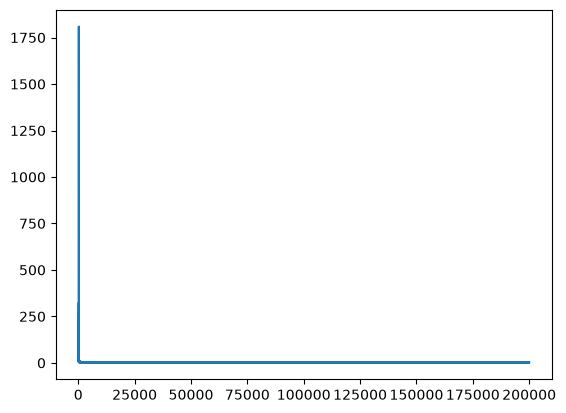

In [13]:
plt.plot(stepi, lossi)

In [14]:
logits.max(1) # check the difference from ys

torch.return_types.max(
values=tensor([4.7056, 5.1317, 3.9284, 2.2800, 3.1334, 3.0159, 4.5326, 3.1795, 2.3541,
        1.8707, 3.0090, 3.4719, 4.3767, 2.7996, 4.5910, 3.8868, 2.4448, 2.7996,
        5.1090, 4.5966, 3.9707, 3.1673, 2.9911, 5.6211, 3.4877, 3.2150, 4.4005,
        3.9318, 3.1508, 3.0238, 2.9824, 0.9968], device='mps:0',
       grad_fn=<MaxBackward0>),
indices=tensor([ 5,  1,  9,  0,  1,  0,  0, 18,  0, 18,  0,  0,  0, 18,  0, 18,  0, 18,
         0,  0,  0,  1,  1,  1, 14, 14,  9,  5,  9,  1,  0,  1],
       device='mps:0'))

In [80]:
# ys

In [16]:
# eval on training set
emb = C[xtr]
h = emb.view(-1, w1.shape[0]) @ w1 + b1
logits = h @ w2 + b2
loss = F.cross_entropy(logits, ytr)
print(loss.item())

2.328113317489624


In [17]:
# eval on dev set
emb = C[xdev]
h = emb.view(-1, w1.shape[0]) @ w1 + b1
logits = h @ w2 + b2
loss = F.cross_entropy(logits, ydev)
print(loss.item())

2.3257203102111816


In [18]:
# eval on test set
emb = C[xtest]
h = emb.view(-1, w1.shape[0]) @ w1 + b1
logits = h @ w2 + b2
loss = F.cross_entropy(logits, ytest)
print(loss.item())

2.3286218643188477


model's loss on 3 data sets are similar and pretty high, try adjusting hyperparameters

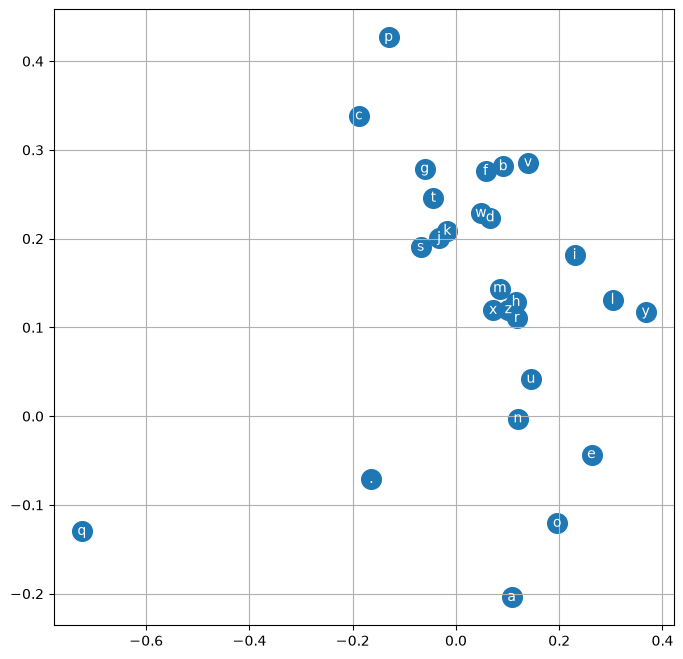

In [20]:
plt.figure(figsize=(8,8))
C = C.cpu()
plt.scatter(C[:,0].data, C[:,1].data, s=200)
for i in range(C.shape[0]):
    plt.text(C[i,0].item(), C[i,1].item(), itos[i], ha="center", va="center", color='white')
plt.grid('minor')

In [21]:
C = C.to(device)

In [22]:
# Sampling
for _ in range(10):
  out = []
  context = [0] * context_size
  while True:
    emb = C[torch.tensor([context])]
    h = torch.tanh(emb.view(1, -1) @ w1 + b1)
    logits = h @ w2 + b2
    probs = F.softmax(logits, dim=1)
    idx = torch.multinomial(probs, num_samples=1, generator=g).item()
    out.append(idx)
    context = context[1:] + [idx]
    if idx == 0:
      break

    print("".join(itos[i] for i in out))

s
se
sei
seim
j
ja
jab
jaba
jabau
jabaun
jabauny
jabaunyi
g
ga
gal
galy
galya
galyat
galyath
b
br
brk
brko
brkoh
brkoha
brkohat
e
el
elc
elct
elcty
o
oh
oht
ohts
e
el
ell
ella
ellae
ellaei
ellaeim
ellaeima
ellaeimat
ellaeimate
ellaeimatei
ellaeimateiy
ellaeimateiym
ellaeimateiymi
ellaeimateiymia
z
zi
zit
zita
zitan
zitanr
zitanri
zitanrio
zitanrion
m
ma
mar
mara
marak
a
al
all
alla
allaz
allaza
allazar
allazarn
